In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

from sklearn.datasets import fetch_openml

cars = fetch_openml(name="autos", version=1, as_frame=True)
df = cars.frame

print(df.head())
print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())



   normalized-losses         make fuel-type aspiration num-of-doors  \
0                NaN  alfa-romero       gas        std          two   
1                NaN  alfa-romero       gas        std          two   
2                NaN  alfa-romero       gas        std          two   
3              164.0         audi       gas        std         four   
4              164.0         audi       gas        std         four   

    body-style drive-wheels engine-location  wheel-base  length  ...  \
0  convertible          rwd           front        88.6   168.8  ...   
1  convertible          rwd           front        88.6   168.8  ...   
2    hatchback          rwd           front        94.5   171.2  ...   
3        sedan          fwd           front        99.8   176.6  ...   
4        sedan          4wd           front        99.4   176.6  ...   

   fuel-system  bore  stroke compression-ratio horsepower  peak-rpm city-mpg  \
0         mpfi  3.47    2.68               9.0      111.0   

In [4]:

from sklearn.datasets import fetch_openml

cars = fetch_openml(name="autos", version=1, as_frame=True)
df = cars.frame

print(df.head())
print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())


   normalized-losses         make fuel-type aspiration num-of-doors  \
0                NaN  alfa-romero       gas        std          two   
1                NaN  alfa-romero       gas        std          two   
2                NaN  alfa-romero       gas        std          two   
3              164.0         audi       gas        std         four   
4              164.0         audi       gas        std         four   

    body-style drive-wheels engine-location  wheel-base  length  ...  \
0  convertible          rwd           front        88.6   168.8  ...   
1  convertible          rwd           front        88.6   168.8  ...   
2    hatchback          rwd           front        94.5   171.2  ...   
3        sedan          fwd           front        99.8   176.6  ...   
4        sedan          4wd           front        99.4   176.6  ...   

   fuel-system  bore  stroke compression-ratio horsepower  peak-rpm city-mpg  \
0         mpfi  3.47    2.68               9.0      111.0   

In [5]:

# Remove columns that contain only missing values
df = df.dropna(axis=1, how="all")

# Fill missing numerical values with the median
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing text values with the most frequent value
for col in df.select_dtypes(include="object").columns:
    if df[col].isnull().any():
        mode_values = df[col].mode()
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values[0])

print("Missing values handled!")
print("\nRemaining missing values:")
print(df.isnull().sum())


Missing values handled!

Remaining missing values:
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         2
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
symboling            0
dtype: int64


In [6]:

print("All columns in the dataset:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


All columns in the dataset:
['normalized-losses', 'make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price', 'symboling']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   normalized-losses  205 non-null    float64 
 1   make               205 non-null    category
 2   fuel-type          205 non-null    category
 3   aspiration         205 non-null    category
 4   num-of-doors       203 non-null    category
 5   body-style         205 non-null    category
 6   drive-wheels       205 non-null    category
 7   engine-location    205 non-null    categ

In [7]:

print("Possible price columns:")
print([col for col in df.columns if "price" in col.lower()])

print("\nFirst 5 rows:")
print(df.head())


Possible price columns:
['price']

First 5 rows:
   normalized-losses         make fuel-type aspiration num-of-doors  \
0              115.0  alfa-romero       gas        std          two   
1              115.0  alfa-romero       gas        std          two   
2              115.0  alfa-romero       gas        std          two   
3              164.0         audi       gas        std         four   
4              164.0         audi       gas        std         four   

    body-style drive-wheels engine-location  wheel-base  length  ...  \
0  convertible          rwd           front        88.6   168.8  ...   
1  convertible          rwd           front        88.6   168.8  ...   
2    hatchback          rwd           front        94.5   171.2  ...   
3        sedan          fwd           front        99.8   176.6  ...   
4        sedan          4wd           front        99.4   176.6  ...   

   fuel-system  bore  stroke compression-ratio horsepower  peak-rpm city-mpg  \
0         m

In [9]:

# Remove rows where the target price is missing
df = df.dropna(subset=["price"]).copy()

# Separate target and input features
y = df["price"]

# Remove price from input features to avoid data leakage
X = df.drop(columns=["price"])

# Convert categorical columns into numeric columns
X = pd.get_dummies(X, drop_first=True)

# Fill any remaining missing feature values
X = X.fillna(X.median())

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nData preparation completed!")


Features shape: (205, 69)
Target shape: (205,)

Data preparation completed!


In [10]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of input features:", X_train.shape[1])


Training samples: 164
Testing samples: 41
Number of input features: 69


In [11]:

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [12]:

# Predict prices for the test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("R2 Score:", round(r2, 4))
print("R2 Score (%):", round(r2 * 100, 2), "%")


Mean Absolute Error (MAE): 2102.36
R2 Score: 0.8643
R2 Score (%): 86.43 %


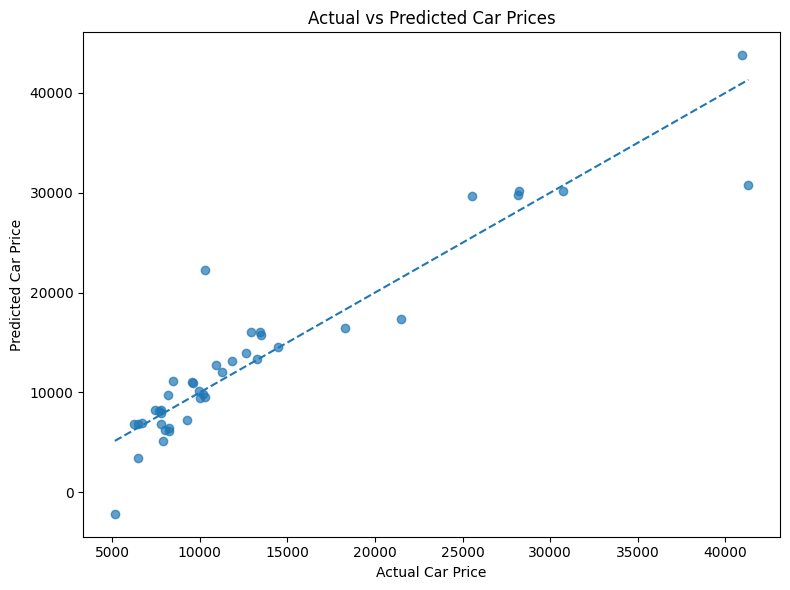

In [13]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")
plt.title("Actual vs Predicted Car Prices")
plt.tight_layout()
plt.show()


In [14]:

# Select one car from the test dataset
sample_car = X_test.iloc[[0]]

# Predict its price
predicted_price = model.predict(sample_car)[0]
actual_price = y_test.iloc[0]

print("Predicted Car Price:", round(predicted_price, 2))
print("Actual Car Price:", round(actual_price, 2))
print("Difference:", round(abs(predicted_price - actual_price), 2))


Predicted Car Price: 30170.04
Actual Car Price: 30760.0
Difference: 589.96
